## TINH CHỈNH THAM SỐ CHO LOGISTIC REGRESSION VÀ TRỰC QUAN HÓA KẾT QUẢ

## CHUẨN BỊ VÀ ĐỌC DỮ LIỆU

In [1]:
from pathlib import Path
import sys
import numpy as np

# Find the project root from the notebook's working directory.
PROJECT_ROOT = Path.cwd().resolve()

# Run until found the (PROJECT_ROOT / "requirements.txt")
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Cannot find the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Allow imports starting with "src".
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"


train_data = np.load(DATA_DIR / "mnist_train.npz")
test_data = np.load(DATA_DIR / "mnist_test.npz")

X_train, y_train = train_data["X"], train_data["y"]
X_test, y_test = test_data["X"], test_data["y"]


SEED = 42
import torch
torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

In [2]:
from src.preprocessing.scaler import split_val, scale_flat

from itertools import product 
import time
from time import perf_counter
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from src.models.logistic_regression import LogisticRegression
from src.evaluation.metrics import ClassificationMetrics

In [3]:
X_train, X_val, y_train, y_val = split_val(X=X_train,y=y_train, val_size=0.1, seed=SEED)
X_train, X_val, X_test,tools = scale_flat(X_train=X_train, X_test=X_test, X_val=X_val, mode="standard")
print(f'Train: {len(X_train)}, Test: {len(X_test)}, Val: {len(X_val)}')

Global Mean: 0.1307, Global Std: 0.3082
Train: 54000, Test: 10000, Val: 6000


## TINH CHỈNH THAM SỐ CHO LOGISTIC REGRESSION

## 1. Import và cấu hình

In [4]:
# Hyperparameters cần tuning
LR_PARAM_GRID = {
    "eta": [0.01, 0.03, 0.1, 0.3],
    "lam": [0.0, 1e-4, 1e-3, 1e-2]
}

# Hyperparameters cố định
LR_FIXED_PARAMS = {
    "max_epochs": 100,
    "batch_size": 128,
    "patience": 6,
    "seed": 42
}

# Baseline
LR_BASELINE = {
    "eta": 0.1,
    "lam": 1e-3
}

LABELS = np.arange(10)

sns.set_theme(style="whitegrid")

## 2. Hàm Grid Search
- Hàm này thử toàn bộ 16 cấu hình, đánh giá bằng ClassificationMetrics và chọn cấu hình có validation accuracy cao nhất.

- Nếu accuracy bằng nhau, ưu tiên Macro F1 cao hơn.

In [5]:
def tune_logistic_regression(X_train, y_train, X_val, y_val):
    """Tinh chỉnh eta và lam bằng Grid Search."""
    results = []
    models = {}

    for eta in LR_PARAM_GRID["eta"]:
        for lam in LR_PARAM_GRID["lam"]:

            model = LogisticRegression(
                eta=eta,
                lam=lam,
                **LR_FIXED_PARAMS
            )

            start_time = time.perf_counter()

            model.fit(
                X_train,
                y_train,
                X_val=X_val,
                y_val=y_val
            )

            train_time = time.perf_counter() - start_time

            # Bỏ qua cấu hình không có epoch hợp lệ
            if model.best_epoch_ is None:
                print(f"Bo qua eta={eta}, lam={lam}")
                continue

            y_pred = model.predict(X_val)

            metrics = ClassificationMetrics(
                y_val,
                y_pred,
                labels=LABELS
            ).evaluate()

            results.append({
                "eta": eta,
                "lam": lam,
                "accuracy": metrics["accuracy"],
                "macro_f1": metrics["macro_f1"],
                "best_epoch": model.best_epoch_,
                "train_time": train_time
            })

            models[(eta, lam)] = model

            print(
                f"eta={eta:<5} | "
                f"lam={lam:<7} | "
                f"Accuracy={metrics['accuracy']:.4f} | "
                f"F1={metrics['macro_f1']:.4f}"
            )

    if not results:
        raise RuntimeError("Khong co cau hinh hop le.")

    results_df = pd.DataFrame(results)

    # Sắp xếp theo Accuracy, sau đó Macro F1
    results_df = results_df.sort_values(
        by=["accuracy", "macro_f1"],
        ascending=False
    ).reset_index(drop=True)

    best_result = results_df.iloc[0]

    best_eta = best_result["eta"]
    best_lam = best_result["lam"]

    best_model = models[(best_eta, best_lam)]

    baseline_model = models[
        (LR_BASELINE["eta"], LR_BASELINE["lam"])
    ]

    return results_df, baseline_model, best_model, best_result

## 3. Biểu đồ 1 — Hyperparameter Heatmap

In [6]:
def plot_tuning_heatmap(results_df, best_result):
    """Vẽ Heatmap Accuracy theo eta và lam."""
    table = results_df.pivot(
        index="eta",
        columns="lam",
        values="accuracy"
    )

    fig, ax = plt.subplots(figsize=(9, 6))

    sns.heatmap(
        table,
        annot=True,
        fmt=".4f",
        cmap="YlGnBu",
        linewidths=0.5,
        cbar_kws={"label": "Validation Accuracy"},
        ax=ax
    )

    ax.set_xlabel("L2 Regularization (lam)")
    ax.set_ylabel("Learning Rate (eta)")
    ax.set_title("Logistic Regression: Hyperparameter Tuning")

    # Đánh dấu ô có cấu hình tốt nhất
    row = list(table.index).index(best_result["eta"])
    col = list(table.columns).index(best_result["lam"])

    ax.add_patch(
        plt.Rectangle(
            (col, row),
            1,
            1,
            fill=False,
            edgecolor="red",
            linewidth=3
        )
    )

    plt.tight_layout()
    plt.show()

## 4. Biểu đồ 2 — Learning Curves
- So sánh quá trình hội tụ của Baseline LR và Tuned LR.

In [7]:
def plot_learning_curves(baseline_model, best_model):
    """So sánh Learning Curves trước và sau tuning."""
    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5),
        sharey=True
    )

    models = [baseline_model, best_model]
    titles = ["Baseline LR", "Tuned LR"]

    for ax, model, title in zip(axes, models, titles):

        history = model.history_

        train_loss = history["train_loss"]
        val_loss = history["val_loss"]

        train_epochs = np.arange(1, len(train_loss) + 1)
        val_epochs = np.arange(1, len(val_loss) + 1)

        sns.lineplot(
            x=train_epochs,
            y=train_loss,
            label="Train Loss (CE + L2)",
            ax=ax
        )

        sns.lineplot(
            x=val_epochs,
            y=val_loss,
            label="Validation Loss (CE)",
            ax=ax
        )

        if model.best_epoch_ is not None:
            ax.axvline(
                model.best_epoch_,
                color="red",
                linestyle="--",
                label=f"Best Epoch: {model.best_epoch_}"
            )

        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_title(title)
        ax.legend()

    fig.suptitle("Logistic Regression: Learning Curves")

    plt.tight_layout()
    plt.show()

## 5. Biểu đồ 3 — Confusion Matrix

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrices(y_val, baseline_pred, best_pred):
    """Vẽ Confusion Matrix trước và sau tuning"""

    predictions = [baseline_pred, best_pred]
    titles = ["Baseline LR", "Tuned LR"]

    # Tính Confusion Matrix cho cả hai mô hình
    matrices = []
    labels_list = []

    for pred in predictions:
        metrics = ClassificationMetrics(
            y_val,
            pred,
            labels=LABELS
        )

        cm, labels = metrics.get_confustion_matrix()

        matrices.append(cm)
        labels_list.append(labels)

    # Sử dụng cùng thang màu cho cả hai Confusion Matrix
    max_value = max(cm.max() for cm in matrices)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    for ax, cm, labels, title in zip(
        axes, matrices, labels_list, titles
    ):
        sns.heatmap(
            cm,
            annot=True,
            fmt=".0f",
            cmap="Blues",
            vmin=0,
            vmax=max_value,
            xticklabels=labels,
            yticklabels=labels,
            cbar=False,
            annot_kws={"size": 8},
            ax=ax
        )

        ax.set_title(title)
        ax.set_xlabel("Predicted Digit")
        ax.set_ylabel("True Digit")

    fig.suptitle(
        "Logistic Regression: Confusion Matrix",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

## 6. Biểu đồ 4 — Per-Class Recall
- So sánh Recall của từng chữ số từ 0 đến 9 trước và sau tuning

In [9]:
def plot_per_class_recall(y_val, baseline_pred, best_pred):
    """So sánh Recall từng lớp trước và sau tuning."""
    baseline_metrics = ClassificationMetrics(
        y_val,
        baseline_pred,
        labels=LABELS
    ).evaluate()

    best_metrics = ClassificationMetrics(
        y_val,
        best_pred,
        labels=LABELS
    ).evaluate()

    baseline_recall = baseline_metrics["recall"]
    best_recall = best_metrics["recall"]

    plot_data = pd.DataFrame({
        "Digit": list(LABELS) * 2,
        "Recall": list(baseline_recall) + list(best_recall),
        "Model": ["Baseline"] * 10 + ["Tuned"] * 10
    })

    fig, ax = plt.subplots(figsize=(11, 5))

    sns.barplot(
        data=plot_data,
        x="Digit",
        y="Recall",
        hue="Model",
        ax=ax
    )

    ax.set_xlabel("Digit")
    ax.set_ylabel("Recall")
    ax.set_title(
        "Logistic Regression: Per-Class Recall Comparison"
    )

    ax.set_ylim(0, 1)
    ax.legend(title="")

    plt.tight_layout()
    plt.show()

## 7. Hàm chạy toàn bộ thí nghiệm

In [10]:
"""Chạy toàn bộ thí nghiệm Logistic Regression."""
# Đưa dữ liệu về NumPy
X_train = np.asarray(X_train)
y_train = np.asarray(y_train, dtype=int)

X_val = np.asarray(X_val)
y_val = np.asarray(y_val, dtype=int)

print("=== LOGISTIC REGRESSION GRID SEARCH ===")

results_df, baseline_model, best_model, best_result = (
    tune_logistic_regression(
        X_train,
        y_train,
        X_val,
        y_val
    )
)

=== LOGISTIC REGRESSION GRID SEARCH ===
Early Stopping tại epoch 46
eta=0.01  | lam=0.0     | Accuracy=0.9210 | F1=0.9201
Early Stopping tại epoch 46
eta=0.01  | lam=0.0001  | Accuracy=0.9210 | F1=0.9201
Early Stopping tại epoch 75
eta=0.01  | lam=0.001   | Accuracy=0.9202 | F1=0.9193
Early Stopping tại epoch 46
eta=0.01  | lam=0.01    | Accuracy=0.9172 | F1=0.9163
Early Stopping tại epoch 26
eta=0.03  | lam=0.0     | Accuracy=0.9208 | F1=0.9200
Early Stopping tại epoch 26
eta=0.03  | lam=0.0001  | Accuracy=0.9205 | F1=0.9196
Early Stopping tại epoch 32
eta=0.03  | lam=0.001   | Accuracy=0.9232 | F1=0.9224
Early Stopping tại epoch 15
eta=0.03  | lam=0.01    | Accuracy=0.9178 | F1=0.9169
Early Stopping tại epoch 16
eta=0.1   | lam=0.0     | Accuracy=0.9197 | F1=0.9188
Early Stopping tại epoch 16
eta=0.1   | lam=0.0001  | Accuracy=0.9197 | F1=0.9188
Early Stopping tại epoch 16
eta=0.1   | lam=0.001   | Accuracy=0.9203 | F1=0.9194
Early Stopping tại epoch 23
eta=0.1   | lam=0.01    | Accu

In [11]:
print("\n=== TUNING RESULTS ===")
results_df


=== TUNING RESULTS ===


,eta,lam,accuracy,macro_f1,best_epoch,train_time
0,0.03,0.0010,0.923167,0.922355,26,7.131562
1,0.01,0.0000,0.921000,0.920144,40,11.758454
2,0.01,0.0001,0.921000,0.920144,40,10.848752
3,0.03,0.0000,0.920833,0.919953,20,6.051590
4,0.03,0.0001,0.920500,0.919623,20,6.292379
5,0.10,0.0010,0.920333,0.919437,10,3.853758
6,0.01,0.0010,0.920167,0.919269,69,16.750197
7,0.10,0.0001,0.919667,0.918756,10,4.059865
8,0.10,0.0000,0.919667,0.918754,10,3.962953
9,0.03,0.0100,0.917833,0.916916,9,3.264758


In [12]:
print("\n=== BEST HYPERPARAMETERS ===")
print(f"Learning Rate: {best_result['eta']}")
print(f"L2 Regularization: {best_result['lam']}")
print(f"Validation Accuracy: {best_result['accuracy']:.4f}")
print(f"Macro F1: {best_result['macro_f1']:.4f}")
print(f"Best Epoch: {int(best_result['best_epoch'])}")


=== BEST HYPERPARAMETERS ===
Learning Rate: 0.03
L2 Regularization: 0.001
Validation Accuracy: 0.9232
Macro F1: 0.9224
Best Epoch: 26


In [13]:
# Dự đoán trên validation set
baseline_pred = baseline_model.predict(X_val)
best_pred = best_model.predict(X_val)

# Đánh giá baseline
baseline_metrics = ClassificationMetrics(
    y_val,
    baseline_pred,
    labels=LABELS
).evaluate()

# Đánh giá tuned model
best_metrics = ClassificationMetrics(
    y_val,
    best_pred,
    labels=LABELS
).evaluate()

comparison = pd.DataFrame({
    "Model": ["Baseline LR", "Tuned LR"],
    "Accuracy": [
        baseline_metrics["accuracy"],
        best_metrics["accuracy"]
    ],
    "Macro F1": [
        baseline_metrics["macro_f1"],
        best_metrics["macro_f1"]
    ],
    "Best Epoch": [
        baseline_model.best_epoch_,
        best_model.best_epoch_
    ]
})

In [14]:
print("\n=== BASELINE VS TUNED ===")
print(comparison.to_string(index=False))


=== BASELINE VS TUNED ===
      Model  Accuracy  Macro F1  Best Epoch
Baseline LR  0.920333  0.919437          10
   Tuned LR  0.923167  0.922355          26


## SỬ DỤNG CÁC HÀM ĐỂ VẼ BIỂU ĐỒ

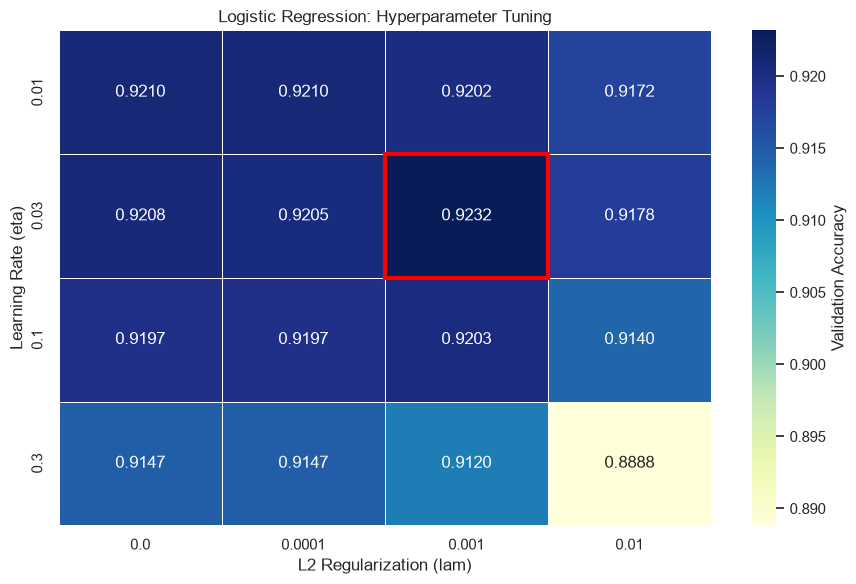

In [15]:
plot_tuning_heatmap(results_df, best_result)

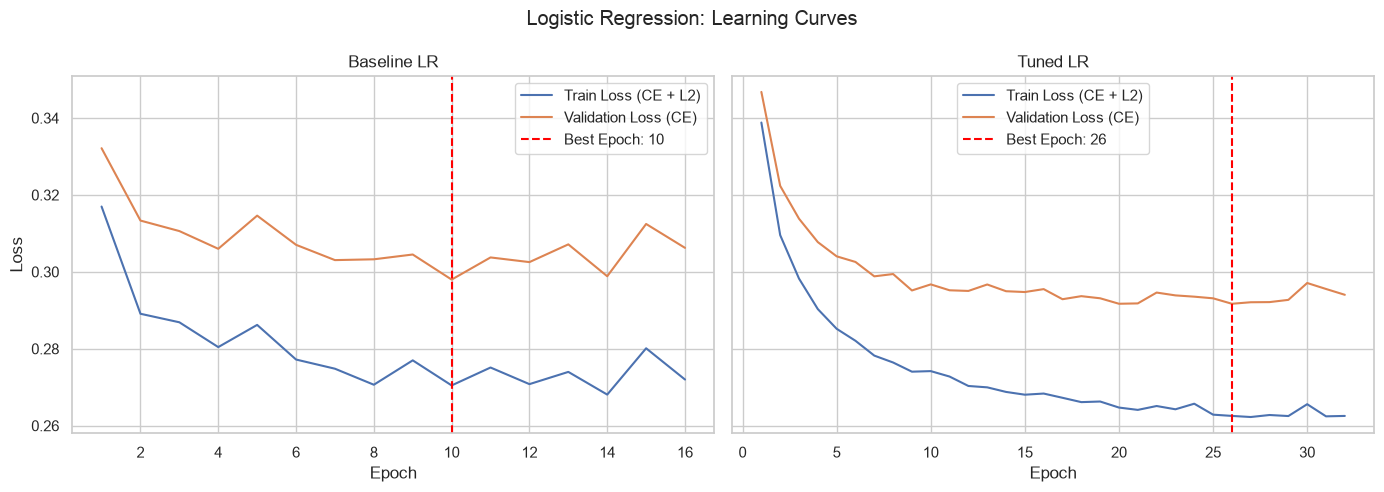

In [16]:
plot_learning_curves(
    baseline_model,
    best_model
)

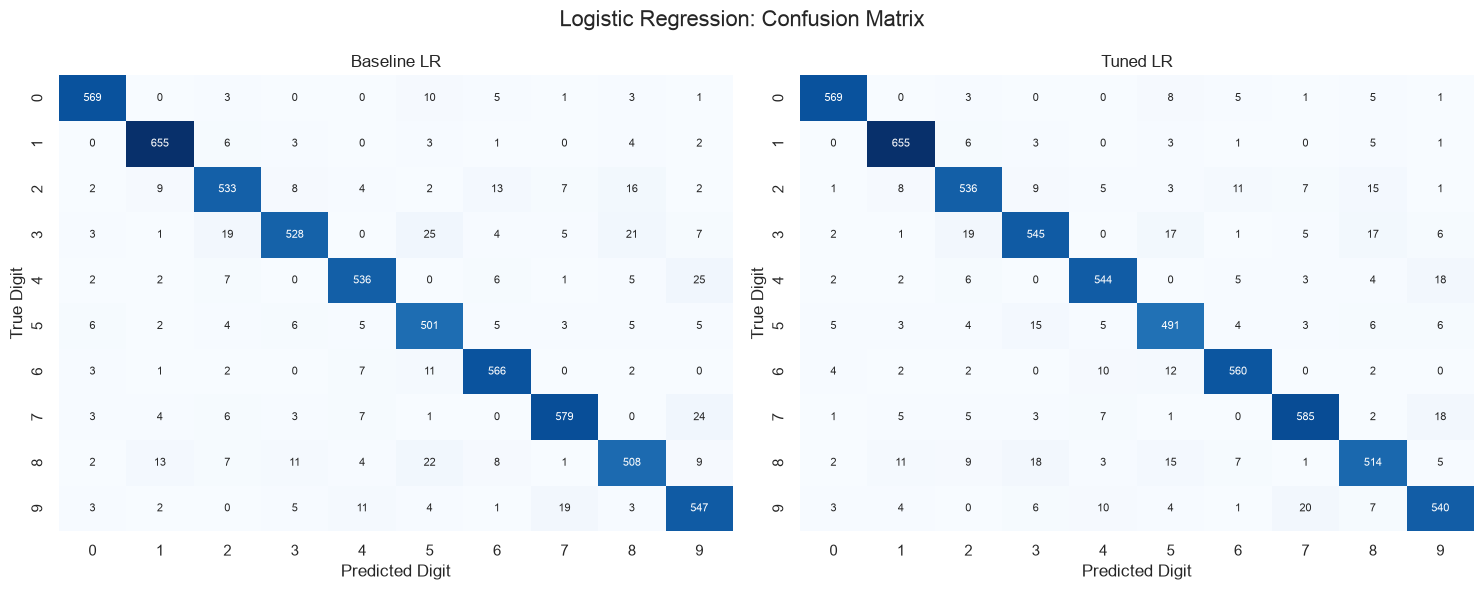

In [17]:
plot_confusion_matrices(
    y_val,
    baseline_pred,
    best_pred
)

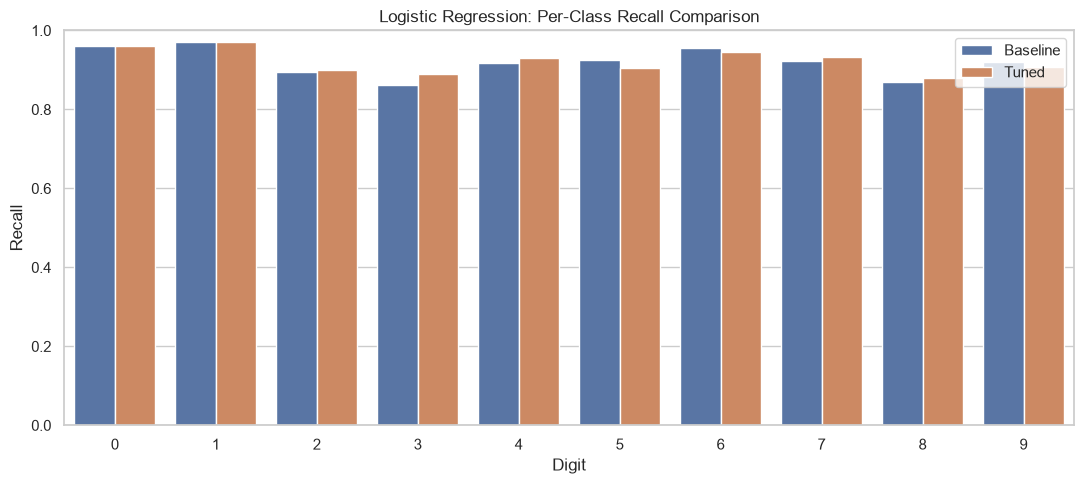

In [18]:
plot_per_class_recall(
    y_val,
    baseline_pred,
    best_pred
)

## DỰ ĐOÁN TRÊN TẬP TEST HOÀN TOÀN CHƯA ĐUỢC NHÌN THẤY

In [19]:
start = time.perf_counter()
y_test_pred = best_model.predict(X_test)
time_pred_lr = time.perf_counter() - start
print(f"time prediction: {time_pred_lr}")
ClassificationMetrics(y_true=y_test, y_pred=y_test_pred).report()

time prediction: 0.027042376000281365
     Class  Precision     Recall         F1
         0      0.959      0.978      0.968 
         1      0.969      0.978      0.973 
         2      0.932      0.907      0.919 
         3      0.907      0.910      0.909 
         4      0.926      0.933      0.929 
         5      0.896      0.871      0.883 
         6      0.935      0.951      0.943 
         7      0.917      0.927      0.922 
         8      0.890      0.886      0.888 
         9      0.912      0.903      0.907 
 Macro avg      0.924      0.924      0.924 

Accuracy: 0.925


## LƯU TRỌNG SỐ MÔ HÌNH

In [20]:
import joblib

# Thiết lập đường dẫn thư mục models
MODELS_DIR = PROJECT_ROOT / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)  # Tự động tạo thư mục nếu chưa tồn tại

print(f"Đang lưu mô hình vào thư mục: {MODELS_DIR.absolute()}")


if 'best_model' in locals():
    nb_path = MODELS_DIR / "logistic_regression.joblib"
    joblib.dump(best_model, nb_path)
    print(f"Đã lưu Logistic Regression tại: {nb_path}")

Đang lưu mô hình vào thư mục: /home/nguyenhaianh/Desktop/Classify_Number/models
Đã lưu Logistic Regression tại: /home/nguyenhaianh/Desktop/Classify_Number/models/logistic_regression.joblib
